In [71]:
import sys
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project')
sys.path.append(r'C:\Users\acostamendoza\projects\distance-project\radial-analysis')
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.data.RadialDevice import RadialDevice
from src.data.WidefieldAligner import WidefieldAligner
from src.data.WidefieldTransformer import WidefieldMapper
from src.viz.CellVisualizer import CellVisualizer
from src.viz.SessionVisualizer import SingleSessionVisualizer, MultiSessionVisualizer
from src.viz.WidefieldVisualizer import WidefieldVisualizer
from src.workflows import load_dataframe

import numpy as np
import matplotlib.pyplot as plt
import pickle
import pandas as pd

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM040'
experiment_name = 'tiling_120um'

combined_df = load_dataframe(mouse_name=mouse_name, experiment_name=experiment_name)
session_df = (
    combined_df[combined_df['session_name'] == '260428_SAM045_tiling_8_120um']
    .drop(columns='session_name')
    .reset_index(drop=True)
)

multi_session_dir = r'D:/data-distance-coding-project/multi-session-data/'
multi_session_dir = os.path.join(multi_session_dir, f'SAM045_{experiment_name}')
alignment_name = f'SAM045_tiling_120um_alignment_parameters.pkl'
alignment_path = os.path.join(multi_session_dir, alignment_name)

with open(alignment_path, 'rb') as f:
    alignment_params = pickle.load(f)
    print(f"Alignment parameters loaded from {alignment_name}")

from src.data.WidefieldTransformer import WidefieldMapper
mapper = WidefieldMapper(alignment_params)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[ok] Loaded DataFrame from D:/data-distance-coding-project/multi-session-data\SAM040_tiling_120um\SAM040_tiling_120um_combined_sessions.pkl (14173 cells)
Alignment parameters loaded from SAM045_tiling_120um_alignment_parameters.pkl


Suite2p stat loaded from D:\data-distance-coding-project\processed-data\260428_SAM044_tiling_8_120um\suite2p\plane0\stat.npy


KeyError: '260428_SAM044_tiling_8_120um'

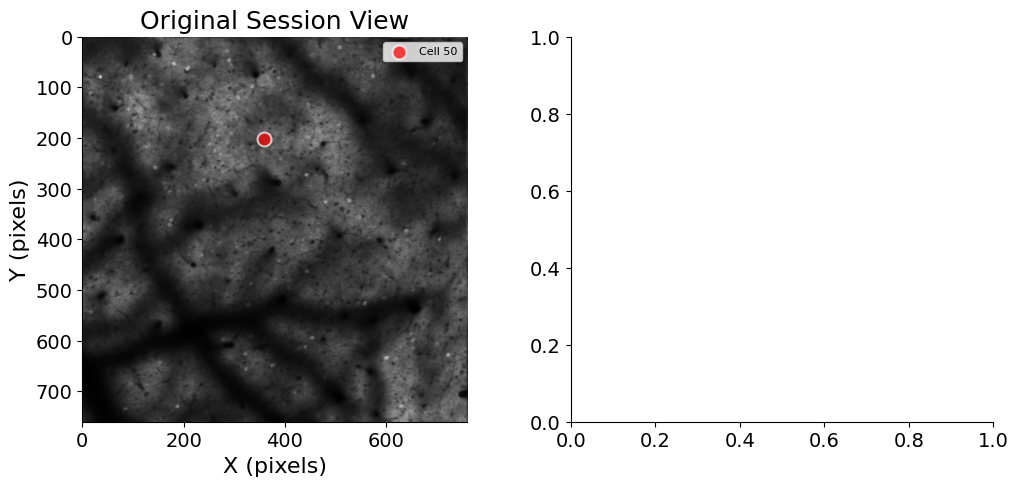

In [69]:
mapper = WidefieldMapper(alignment_params)
mapper.plot_cell_in_widefield('260428_SAM044_tiling_8_120um', (50))
mapper.plot_cell_in_retinotopy_maps('260428_SAM044_tiling_8_120um', 0, session_df=session_df)

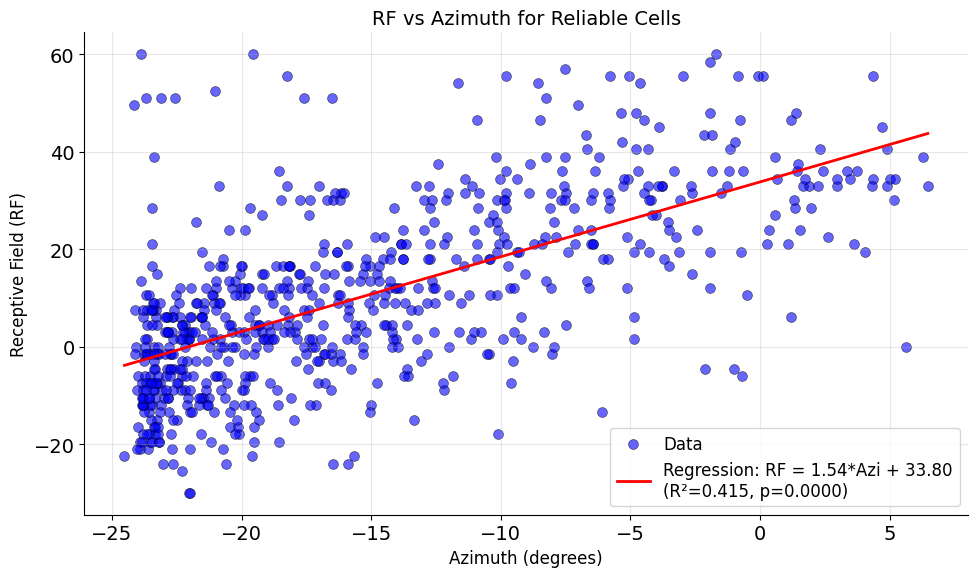

Plotted 702 reliable cells
Regression: RF ≈ 1.54 * Azimuth + 33.80
R² = 0.4153, p-value = 0.0000


In [231]:
# Plot relationship between cell's RF and its azimuth location with regression

# Get reliable cells
reliable_cells = reliable_classes['reliable']

# Extract RF and azimuth values for reliable cells
rf_values = []
azi_values = []

for cell_id in reliable_cells:
    cell_row = session_df[session_df['cell_id'] == cell_id]
    if len(cell_row) > 0 and 'azi' in cell_row.columns:
        # Get RF value (using binocular condition as default)
        rf = cell_row['binocular'].values[0].get('RF', None)
        azi = cell_row['azi'].values[0]
        
        if rf is not None and azi is not None and not np.isnan(rf) and not np.isnan(azi):
            rf_values.append(rf)
            azi_values.append(azi)

# Convert to numpy arrays for regression
rf_values = np.array(rf_values)
azi_values = np.array(azi_values)

# Perform linear regression
from scipy import stats
slope, intercept, r_value, p_value, std_err = stats.linregress(azi_values, rf_values)

# Create regression line
azi_line = np.linspace(azi_values.min(), azi_values.max(), 100)
rf_line = slope * azi_line + intercept

# Create scatter plot with regression line
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(azi_values, rf_values, alpha=0.6, s=50, c='blue', edgecolors='black', linewidth=0.5, label='Data')
ax.plot(azi_line, rf_line, 'r-', linewidth=2, label=f'Regression: RF = {slope:.2f}*Azi + {intercept:.2f}\n(R²={r_value**2:.3f}, p={p_value:.4f})')
ax.set_xlabel('Azimuth (degrees)', fontsize=12)
ax.set_ylabel('Receptive Field (RF)', fontsize=12)
ax.set_title('RF vs Azimuth for Reliable Cells', fontsize=14)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Plotted {len(rf_values)} reliable cells")
print(f"Regression: RF ≈ {slope:.2f} * Azimuth + {intercept:.2f}")
print(f"R² = {r_value**2:.4f}, p-value = {p_value:.4f}")